In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyas actividades y duraciones (días) se adjuntan. Sus prelaciones no son todas del tipo habitual: el segundo cuadro las describe con el *método de diagramación por precedencias* (PDM), donde cada relación tiene un tipo y un desfase (en días):

- **FC** (fin-comienzo) + d: la sucesora empieza al menos d días después de que termine la predecesora (FC + 0 es la prelación ordinaria);
- **CC** (comienzo-comienzo) + d: la sucesora empieza al menos d días después de que *empiece* la predecesora (solape);
- **FF** (fin-fin) + d: la sucesora termina al menos d días después de que termine la predecesora;
- **CF** (comienzo-fin) + d: la sucesora termina al menos d días después de que empiece la predecesora.

Las actividades no se interrumpen.

In [4]:
pregunta_1 = "1. Escriba, para cada tipo de relación, la condición que impone sobre el inicio más temprano de la sucesora (ES) en función de ES, EF y la duración. Calcule el paso hacia delante (ES, EF) en orden topológico, anotando los candidatos de cada actividad.  "
pregunta_2 = "2. Escriba las condiciones del paso hacia atrás (LS, LF) para cada tipo y calcúlelo. Obtenga las holguras totales y la duración del proyecto.  "
pregunta_3 = "3. ¿Cuál es el camino crítico? ¿Hay alguna actividad crítica que no esté *entera* en él, es decir, cuya criticidad venga de un solape (CC o FF)? ¿Qué pasaría con el plazo si esa actividad se alargara?  "
pregunta_4 = "4. Sustituya todas las relaciones por FC + 0 (las prelaciones clásicas) y calcule la duración con la librería. ¿Por qué difiere? ¿Qué relaciones acortan y cuáles alargan el proyecto?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Escriba, para cada tipo de relación, la condición que impone sobre el inicio más temprano de la sucesora (ES) en función de ES, EF y la duración. Calcule el paso hacia delante (ES, EF) en orden topológico, anotando los candidatos de cada actividad.  

2. Escriba las condiciones del paso hacia atrás (LS, LF) para cada tipo y calcúlelo. Obtenga las holguras totales y la duración del proyecto.  

3. ¿Cuál es el camino crítico? ¿Hay alguna actividad crítica que no esté *entera* en él, es decir, cuya criticidad venga de un solape (CC o FF)? ¿Qué pasaría con el plazo si esa actividad se alargara?  

4. Sustituya todas las relaciones por FC + 0 (las prelaciones clásicas) y calcule la duración con la librería. ¿Por qué difiere? ¿Qué relaciones acortan y cuáles alargan el proyecto?  

In [5]:
#| tbl-cap: "Actividades y duraciones"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 8       ),
    ('B'     , '---'      , 8       ),
    ('C'     , 'A'        , 7       ),
    ('D'     , 'B,C'      , 3       ),
    ('E'     , 'D'        , 4       ),
    ('F'     , 'E'        , 5       ),
    ('G'     , 'F'        , 8       ),
    ('H'     , 'F'        , 6       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
datos_enunciado

,predecessor,duration
activity,,
A,---,8
B,---,8
C,A,7
D,"B,C",3
E,D,4
F,E,5
G,F,8
H,F,6


In [6]:
#| tbl-cap: "Relaciones PDM"
#| label: tbl-relaciones
relaciones = pd.DataFrame([
#  id, predecessor, successor, type, lag
    (1 , 'A'        , 'C'      , 'FF', 2  ),
    (2 , 'B'        , 'D'      , 'FC', 0  ),
    (3 , 'C'        , 'D'      , 'CC', 2  ),
    (4 , 'D'        , 'E'      , 'FC', 1  ),
    (5 , 'E'        , 'F'      , 'FC', 0  ),
    (6 , 'F'        , 'G'      , 'FC', 0  ),
    (7 , 'F'        , 'H'      , 'CF', 7  ),
], columns=['id', 'predecessor', 'successor', 'type', 'lag']).set_index('id')
relaciones

,predecessor,successor,type,lag
id,,,,
1,A,C,FF,2
2,B,D,FC,0
3,C,D,CC,2
4,D,E,FC,1
5,E,F,FC,0
6,F,G,FC,0
7,F,H,CF,7


# Resolución

In [7]:
datos_proyecto = datos_enunciado.copy()

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Escriba, para cada tipo de relación, la condición que impone sobre el inicio más temprano de la sucesora (ES) en función de ES, EF y la duración. Calcule el paso hacia delante (ES, EF) en orden topológico, anotando los candidatos de cada actividad.  

Condiciones sobre la sucesora $a$ con predecesora $p$ y desfase $\ell$:

| tipo | condición | sobre ES(a) |
|---|---|---|
| FC | $ES_a \ge EF_p + \ell$ | $EF_p + \ell$ |
| CC | $ES_a \ge ES_p + \ell$ | $ES_p + \ell$ |
| FF | $EF_a \ge EF_p + \ell$ | $EF_p + \ell - d_a$ |
| CF | $EF_a \ge ES_p + \ell$ | $ES_p + \ell - d_a$ |

ES es el máximo de los candidatos (y 0 si no hay ninguno); EF = ES + d.

In [9]:
def calendario_pdm(datos, relaciones):
    '''Pasos hacia delante y hacia atrás con relaciones FC/CC/FF/CF y desfases (sin interrumpir actividades).'''
    d = datos['duration'].astype(int).to_dict()
    G = nx.DiGraph(); G.add_nodes_from(d)
    for _, r in relaciones.iterrows():
        G.add_edge(r['predecessor'], r['successor'], tipo=r['type'], lag=int(r['lag']))
    orden = list(nx.topological_sort(G))
    ES, EF, como = {}, {}, {}
    for a in orden:
        cands = {'inicio del proyecto': 0}
        for p, _, e in G.in_edges(a, data=True):
            tipo, lag = e['tipo'], e['lag']
            if tipo == 'FC': v, f = EF[p] + lag, f'EF({p}) + {lag}'
            elif tipo == 'CC': v, f = ES[p] + lag, f'ES({p}) + {lag}'
            elif tipo == 'FF': v, f = EF[p] + lag - d[a], f'EF({p}) + {lag} − d({a})'
            else: v, f = ES[p] + lag - d[a], f'ES({p}) + {lag} − d({a})'
            cands[f'{tipo} desde {p}: {f} = {v}'] = v
        ES[a] = max(cands.values()); EF[a] = ES[a] + d[a]
        como[a] = '; '.join(k for k in cands if k != 'inicio del proyecto') or 'inicial'
    T = max(EF.values())
    LS, LF, como_t = {}, {}, {}
    for a in reversed(orden):
        cands = {'fin del proyecto': T}
        for _, s, e in G.out_edges(a, data=True):
            tipo, lag = e['tipo'], e['lag']
            if tipo == 'FC': v, f = LS[s] - lag, f'LS({s}) − {lag}'
            elif tipo == 'CC': v, f = LS[s] - lag + d[a], f'LS({s}) − {lag} + d({a})'
            elif tipo == 'FF': v, f = LF[s] - lag, f'LF({s}) − {lag}'
            else: v, f = LF[s] - lag + d[a], f'LF({s}) − {lag} + d({a})'
            cands[f'{tipo} hacia {s}: {f} = {v}'] = v
        LF[a] = min(cands.values()); LS[a] = LF[a] - d[a]
        como_t[a] = '; '.join(k for k in cands if k != 'fin del proyecto') or 'final'
    cal = pd.DataFrame({'ES': ES, 'EF': EF, 'LS': LS, 'LF': LF}).loc[list(d)]
    cal['H_total'] = cal['LS'] - cal['ES']
    detalle = pd.DataFrame({'ES = máx(…)': como, 'LF = mín(…)': como_t}).loc[list(d)]
    return cal, detalle, T

In [10]:
#| tbl-cap: "Calendario PDM"
#| label: tbl-calendarioPdm
calendario, detalle, duracion_pdm = calendario_pdm(datos_proyecto, relaciones)
calendario

,ES,EF,LS,LF,H_total
A,0,8,3,11,3
B,0,8,0,8,0
C,3,10,6,13,3
D,8,11,8,11,0
E,12,16,12,16,0
F,16,21,16,21,0
G,21,29,21,29,0
H,17,23,23,29,6


In [11]:
#| tbl-cap: "Candidatos considerados en cada actividad"
#| label: tbl-candidatos
detalle

,ES = máx(…),LF = mín(…)
A,inicial,FF hacia C: LF(C) − 2 = 11
B,inicial,FC hacia D: LS(D) − 0 = 8
C,FF desde A: EF(A) + 2 − d(C) = 3,CC hacia D: LS(D) − 2 + d(C) = 13
D,FC desde B: EF(B) + 0 = 8; CC desde C: ES(C) +...,FC hacia E: LS(E) − 1 = 11
E,FC desde D: EF(D) + 1 = 12,FC hacia F: LS(F) − 0 = 16
F,FC desde E: EF(E) + 0 = 16,FC hacia G: LS(G) − 0 = 21; CF hacia H: LF(H) ...
G,FC desde F: EF(F) + 0 = 21,final
H,CF desde F: ES(F) + 7 − d(H) = 17,final


## Apartado 2

In [12]:
display(Markdown(pregunta_2))

2. Escriba las condiciones del paso hacia atrás (LS, LF) para cada tipo y calcúlelo. Obtenga las holguras totales y la duración del proyecto.  

Hacia atrás, cada relación acota la predecesora: FC: $LF_p \le LS_a - \ell$; CC: $LS_p \le LS_a - \ell$ (luego $LF_p \le LS_a - \ell + d_p$); FF: $LF_p \le LF_a - \ell$; CF: $LS_p \le LF_a - \ell$. LF es el mínimo (la duración del proyecto si no hay sucesoras) y LS = LF − d. La holgura total es LS − ES.

In [13]:
Markdown(f'La duración del proyecto es {duracion_pdm} días. Actividades críticas (holgura 0): {", ".join(calendario.index[calendario["H_total"] == 0])}.')

La duración del proyecto es 29 días. Actividades críticas (holgura 0): B, D, E, F, G.

## Apartado 3

In [14]:
display(Markdown(pregunta_3))

3. ¿Cuál es el camino crítico? ¿Hay alguna actividad crítica que no esté *entera* en él, es decir, cuya criticidad venga de un solape (CC o FF)? ¿Qué pasaría con el plazo si esa actividad se alargara?  

In [15]:
criticas = calendario.index[calendario['H_total'] == 0].tolist()
rel_crit = relaciones[relaciones['predecessor'].isin(criticas) & relaciones['successor'].isin(criticas)].copy()
# una relación es 'activa' si se cumple con igualdad en el calendario temprano
def activa(r):
    p, s, t, l = r['predecessor'], r['successor'], r['type'], int(r['lag'])
    ES, EF = calendario['ES'], calendario['EF']
    return {'FC': ES[s] == EF[p] + l, 'CC': ES[s] == ES[p] + l, 'FF': EF[s] == EF[p] + l, 'CF': EF[s] == ES[p] + l}[t]
rel_crit['activa'] = rel_crit.apply(activa, axis=1)
display(rel_crit)
solapes = rel_crit[rel_crit['activa'] & rel_crit['type'].isin(['CC', 'FF', 'CF'])]
Markdown('Camino crítico: la cadena de relaciones activas entre actividades críticas. ' + (
    f'Las relaciones {", ".join(f"{r.predecessor}→{r.successor} ({r.type})" for r in solapes.itertuples())} no son fin-comienzo: en ellas sólo es crítico el extremo que la relación une. '
    'Con CC, el *inicio* de la predecesora (alargarla no retrasa el proyecto, salvo que otra relación lo impida); con FF, su *fin* (acortarla no adelanta nada); '
    'con CF, el inicio de la predecesora y el fin de la sucesora. Es la paradoja del PDM: una actividad crítica puede alargarse sin retrasar el plazo.'
    if len(solapes) else 'Todas las relaciones activas del camino crítico son FC: el camino crítico se comporta como en el PERT clásico.'))

,predecessor,successor,type,lag,activa
id,,,,,
2,B,D,FC,0,True
4,D,E,FC,1,True
5,E,F,FC,0,True
6,F,G,FC,0,True


Camino crítico: la cadena de relaciones activas entre actividades críticas. Todas las relaciones activas del camino crítico son FC: el camino crítico se comporta como en el PERT clásico.

## Apartado 4

In [16]:
display(Markdown(pregunta_4))

4. Sustituya todas las relaciones por FC + 0 (las prelaciones clásicas) y calcule la duración con la librería. ¿Por qué difiere? ¿Qué relaciones acortan y cuáles alargan el proyecto?  

In [17]:
tabla_fc = datos_proyecto.copy()
tabla_fc['predecessor'] = [','.join(sorted(relaciones.loc[relaciones['successor'] == a, 'predecessor'])) or '---' for a in tabla_fc.index]
proyecto_fc = PredecessorTable.from_dataframe_of_strings(tabla_fc, activity='activity', predecessor='predecessor').create_project()
duracion_fc = proyecto_fc.duration(tabla_fc['duration'])
calendario_fc = proyecto_fc.calendar(tabla_fc['duration'])
comparacion = pd.DataFrame({'ES (PDM)': calendario['ES'], 'ES (todo FC+0)': calendario_fc['inicio_mas_temprano'], 'H_total (PDM)': calendario['H_total'], 'H_total (todo FC+0)': calendario_fc['H_total']})
display(comparacion)
Markdown(f'''Con todas las relaciones FC + 0 el proyecto dura {duracion_fc} días frente a {duracion_pdm} con PDM. Las relaciones CC y FF permiten solapar actividades (acortan); los desfases positivos en FC son esperas obligadas (alargan); una CF con desfase grande obliga a que la sucesora no termine demasiado pronto, lo que puede retrasarla respecto al FC clásico. El efecto neto depende de cuáles de ellas están en el camino crítico.''')

,ES (PDM),ES (todo FC+0),H_total (PDM),H_total (todo FC+0)
A,0,0,3,0
B,0,0,0,7
C,3,8,3,0
D,8,15,0,0
E,12,18,0,0
F,16,22,0,0
G,21,27,0,0
H,17,27,6,2


Con todas las relaciones FC + 0 el proyecto dura 35 días frente a 29 con PDM. Las relaciones CC y FF permiten solapar actividades (acortan); los desfases positivos en FC son esperas obligadas (alargan); una CF con desfase grande obliga a que la sucesora no termine demasiado pronto, lo que puede retrasarla respecto al FC clásico. El efecto neto depende de cuáles de ellas están en el camino crítico.

In [ ]:
proyecto_fc.display_roy_pasos(tabla_fc['duration'])

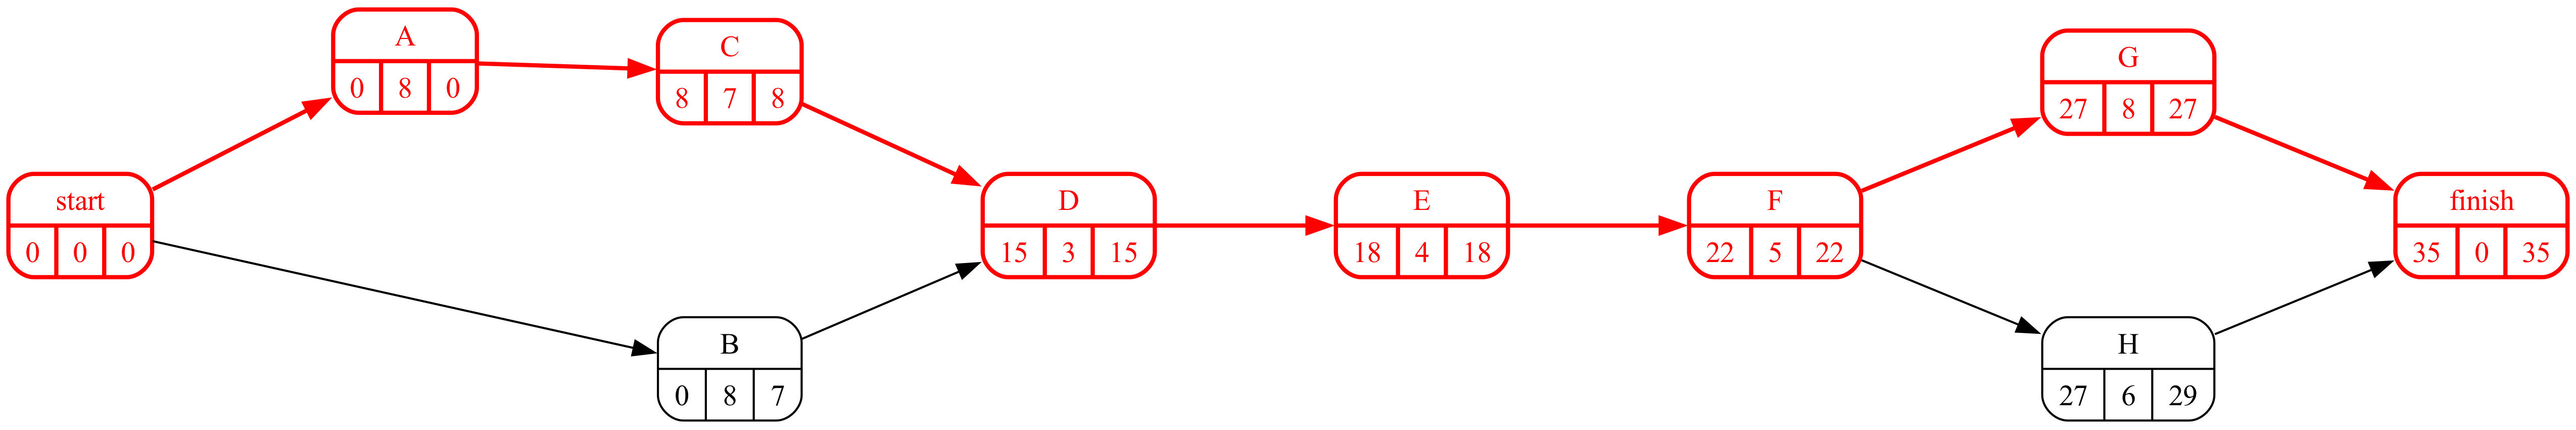

In [18]:
#| fig-cap: "Grafo Roy equivalente con todas las relaciones FC + 0"
#| label: fig-pertFc
proyecto_fc.roy(durations=tabla_fc['duration'], ranksep=1.2, nodesep=1.2)